# mwp_converter demo (QUICK)
Модель радиофотонного многодиапазонного преобразователя. Физика — в пакете `mwp_converter`; подробности в README.

In [1]:
import sys
sys.path.insert(0, '..')
from mwp_converter.params import load_config, quick, fs_GHz
cfg = quick(load_config('../configs/default.toml'))
print(cfg.plan, 'fs =', fs_GHz(cfg.plan, cfg.sim), 'GHz')

Plan(fc_GHz=30.0, f_lo_GHz=(5.5, 9.0, 17.0), direction='lower', wdm_spacing_GHz=100.0) fs = 396.0 GHz


In [2]:
from mwp_converter.model import simulate
res, tx, fs = simulate(cfg.plan, cfg.sim, cfg.imp, cfg.comps, 0)
print(res.meta, res.I.shape)

{'channel': 0, 'bias1': 'null', 'SpS': 396} (811008,)


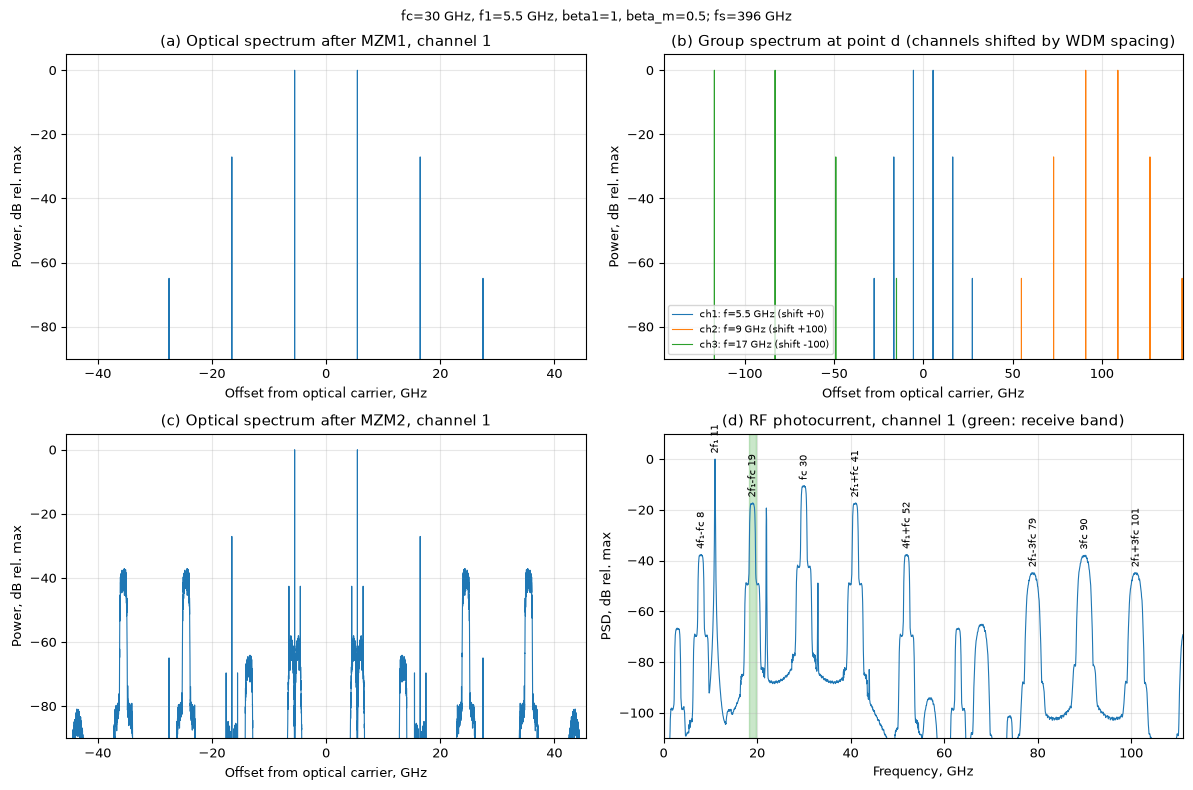

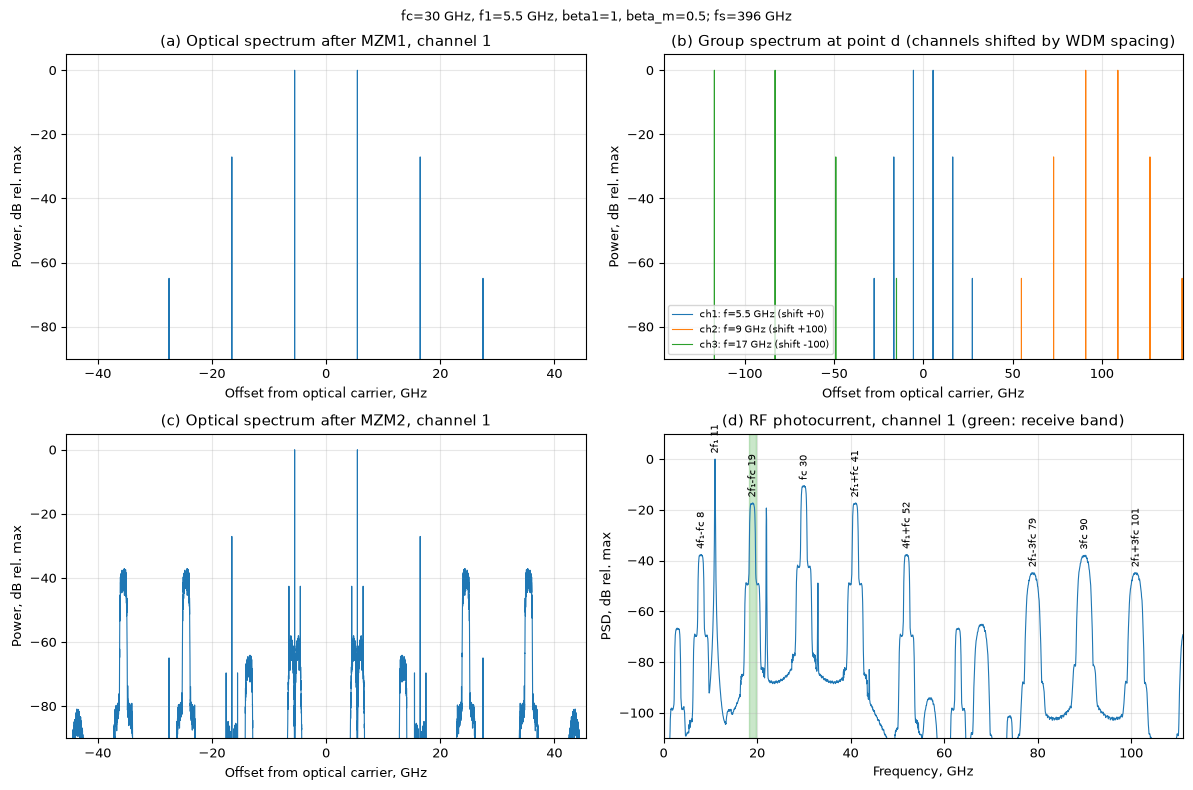

In [3]:
from mwp_converter import plots
%matplotlib inline
from IPython.display import display
figs, rows = plots.fig1(cfg, True)
display(figs[0][1])

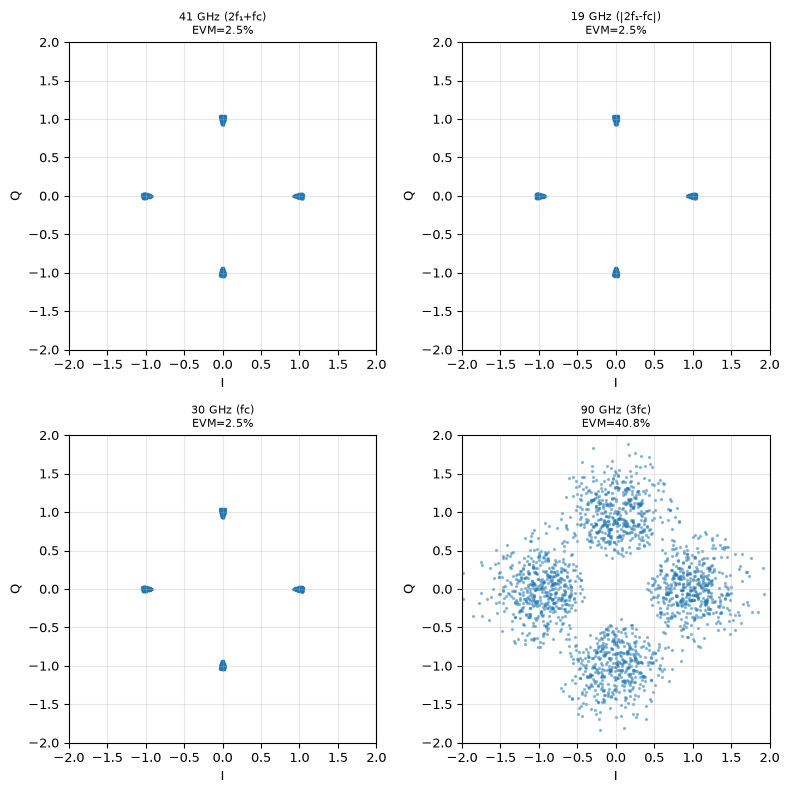

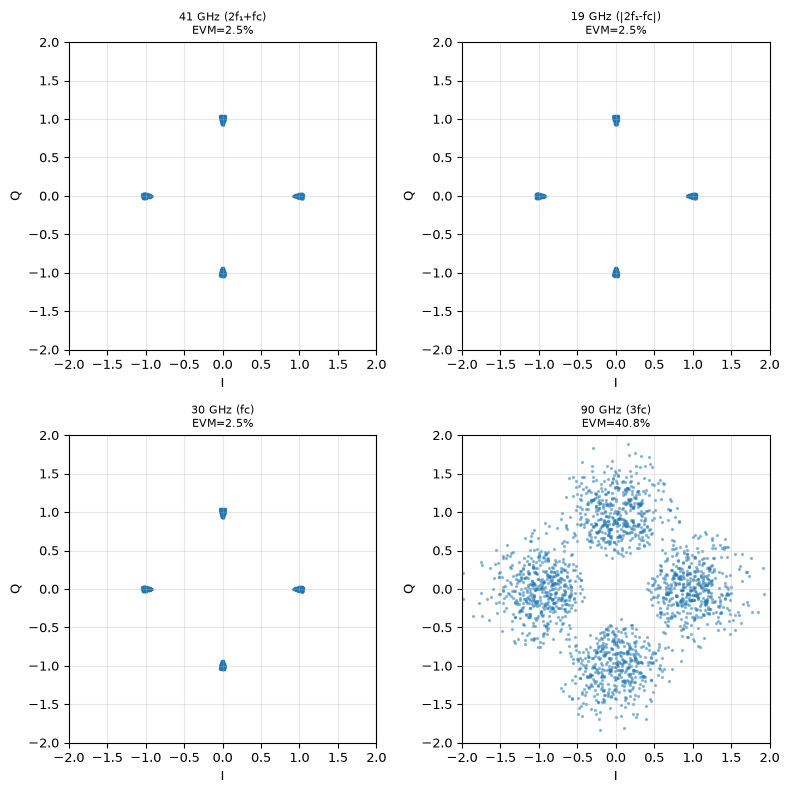

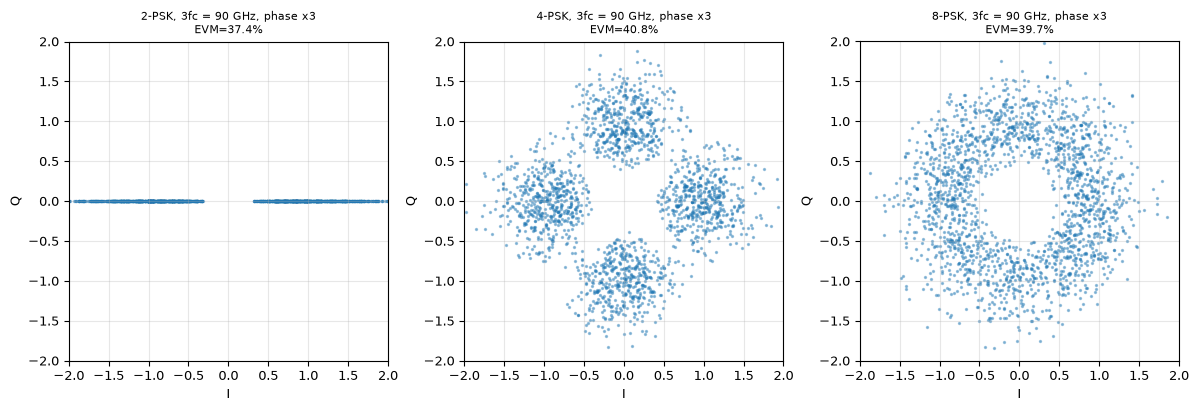

In [4]:
figs, rows = plots.fig3(cfg, True)
display(figs[0][1])

In [5]:
from dataclasses import replace
from mwp_converter.analytic import lines_null
from mwp_converter.model import measure_lines
from mwp_converter.params import Components
plan = replace(cfg.plan, f_lo_GHz=(9.0,))
names = ['DC', '2fi', 'fc', '2fi+fc', '3fc']
meas = measure_lines(0, plan, cfg.sim, Components(), names)
ref = lines_null(1.0, 0.5)
for n in names:
    print(f'{n:8s} model {meas[n][1]:.5f}   (13\') {ref[n]:.5f}')

DC       model 0.77611   (13') 0.77611
2fi      model 0.70567   (13') 0.70567
fc       model 0.68305   (13') 0.68305
2fi+fc   model 0.31053   (13') 0.31053
3fc      model 0.03037   (13') 0.03037
